
# Project: Eco-Health Risk Predictor

## Step 1: Introduction and Dataset Overview

In this project, we will develop an end-to-end machine learning classification system to predict health-impact risk classes using environmental and air-quality measurements.

### Dataset Description

We are using the Air Quality and Health Impact Dataset from Kaggle. The dataset contains environmental measurements and health-impact information.

The features may include:

- **AQI (Air Quality Index):** An indicator of overall air pollution.
- **PM2.5 and PM10:** Particulate matter present in the air.
- **NO2, SO2, and O3:** Atmospheric gases associated with air quality.
- **Health-impact variables:** Additional variables describing the recorded health impact.

### Project Objectives

1. Load and inspect the dataset.
2. Identify missing values, duplicate records, and data-quality issues.
3. Explore the distribution of health-impact classes.
4. Select appropriate features and prevent target leakage.
5. Train a Random Forest classification model.
6. Evaluate the model using appropriate classification metrics.
7. Visualize the confusion matrix and feature importance.
8. Interpret the results and document the limitations.



## Step 2: Import Libraries and Load the Dataset

In this step, we import the Python libraries required for data manipulation, visualization, and machine learning.

- **Pandas:** Loads and manages tabular data.
- **NumPy:** Supports numerical operations.
- **Matplotlib and Seaborn:** Create charts and visualizations.
- **Scikit-learn:** Provides data-splitting tools, preprocessing pipelines, machine learning models, and evaluation metrics.

We then load the CSV file into a Pandas DataFrame and inspect its dimensions, column names, and first few records.

This initial inspection helps us understand the structure of the dataset before performing further analysis.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score
)

sns.set_theme(style="whitegrid")

df = pd.read_csv("air_quality_health_impact_data.csv")
df.columns = df.columns.astype(str).str.strip()
df = df.replace([np.inf, -np.inf], np.nan)

print("Dataset loaded successfully.")
print(f"Total rows: {df.shape[0]}")
print(f"Total columns: {df.shape[1]}")

display(df.head())
print("Column names:", df.columns.tolist())

Dataset loaded successfully.
Total rows: 5811
Total columns: 15


,RecordID,AQI,PM10,PM2_5,NO2,SO2,O3,Temperature,Humidity,WindSpeed,RespiratoryCases,CardiovascularCases,HospitalAdmissions,HealthImpactScore,HealthImpactClass
0,1,187.270059,295.853039,13.038560,6.639263,66.161150,54.624280,5.150335,84.424344,6.137755,7,5,1,97.244041,0.0
1,2,475.357153,246.254703,9.984497,16.318326,90.499523,169.621728,1.543378,46.851415,4.521422,10,2,0,100.000000,0.0
2,3,365.996971,84.443191,23.111340,96.317811,17.875850,9.006794,1.169483,17.806977,11.157384,13,3,0,100.000000,0.0
3,4,299.329242,21.020609,14.273403,81.234403,48.323616,93.161033,21.925276,99.473373,15.302500,8,8,1,100.000000,0.0
4,5,78.009320,16.987667,152.111623,121.235461,90.866167,241.795138,9.217517,24.906837,14.534733,9,0,1,95.182643,0.0


Column names: ['RecordID', 'AQI', 'PM10', 'PM2_5', 'NO2', 'SO2', 'O3', 'Temperature', 'Humidity', 'WindSpeed', 'RespiratoryCases', 'CardiovascularCases', 'HospitalAdmissions', 'HealthImpactScore', 'HealthImpactClass']



## Step 3: Data Quality Assessment

Before training a machine learning model, we need to examine the quality and completeness of the dataset.

The following checks will identify:

- **Missing values:** Entries that contain no recorded value.
- **Duplicate records:** Rows that appear more than once.
- **Data types:** Whether columns contain numerical, categorical, or other data.
- **Statistical summaries:** Measures such as the mean, standard deviation, minimum, and maximum for numerical variables.

These checks help identify potential data problems that could affect model training and evaluation.

Missing values and duplicate records will be investigated rather than removed automatically without justification.


In [2]:
print("Missing values:")
display(df.isnull().sum().to_frame("Missing Values"))

print("Duplicate rows:", df.duplicated().sum())

print("Dataset information:")
df.info()

print("Statistical summary:")
display(df.describe(include="all").T)

Missing values:


,Missing Values
RecordID,0
AQI,0
PM10,0
PM2_5,0
NO2,0
SO2,0
O3,0
Temperature,0
Humidity,0
WindSpeed,0


Duplicate rows: 0
Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 5811 entries, 0 to 5810
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   RecordID             5811 non-null   int64  
 1   AQI                  5811 non-null   float64
 2   PM10                 5811 non-null   float64
 3   PM2_5                5811 non-null   float64
 4   NO2                  5811 non-null   float64
 5   SO2                  5811 non-null   float64
 6   O3                   5811 non-null   float64
 7   Temperature          5811 non-null   float64
 8   Humidity             5811 non-null   float64
 9   WindSpeed            5811 non-null   float64
 10  RespiratoryCases     5811 non-null   int64  
 11  CardiovascularCases  5811 non-null   int64  
 12  HospitalAdmissions   5811 non-null   int64  
 13  HealthImpactScore    5811 non-null   float64
 14  HealthImpactClass    5811 non-null   float64
dtypes: float64

,count,mean,std,min,25%,50%,75%,max
RecordID,5811.0,2906.000000,1677.635538,1.000000,1453.500000,2906.000000,4358.500000,5811.000000
AQI,5811.0,248.438476,144.777638,0.005817,122.951293,249.127841,373.630668,499.858837
PM10,5811.0,148.654997,85.698500,0.015848,75.374954,147.634997,222.436759,299.901962
PM2_5,5811.0,100.223714,58.096612,0.031549,49.435171,100.506337,151.340260,199.984965
NO2,5811.0,102.293445,57.713175,0.009625,53.538538,102.987736,151.658516,199.980195
SO2,5811.0,49.456838,28.530329,0.011023,24.887264,49.530165,73.346617,99.969561
O3,5811.0,149.312431,86.534240,0.001661,73.999665,149.559871,223.380126,299.936812
Temperature,5811.0,14.975500,14.483067,-9.990998,2.481500,14.942428,27.465374,39.963434
Humidity,5811.0,54.776853,26.020786,10.001506,31.995262,54.543904,77.641639,99.997493
WindSpeed,5811.0,9.989177,5.776950,0.002094,4.952343,10.051742,14.971840,19.999139



## Step 4: Target Identification and Class Distribution

The target variable is the outcome that the machine learning model will attempt to predict.

The notebook checks the available column names to identify the appropriate health-impact classification target. It does not automatically select the last column if the expected target is missing.

We then examine the unique target values and count the records belonging to each class.

### Why Is Class Distribution Important?

A dataset may contain many examples of one class but very few examples of another. This is known as **class imbalance**.

A model trained on an imbalanced dataset may perform well overall while failing to identify less frequent classes.

The class-distribution chart will help us understand the balance of the target classes before training the model.

Class labels will be assigned only when the observed target values match the expected encoding; otherwise, the values must be checked against the dataset documentation.


Target column: HealthImpactClass
Observed target values: [0.0, 1.0, 2.0, 3.0, 4.0]


,Number of Records
HealthImpactClass,
Very High Risk,4808
High Risk,579
Moderate Risk,273
Low Risk,95
Very Low Risk,56


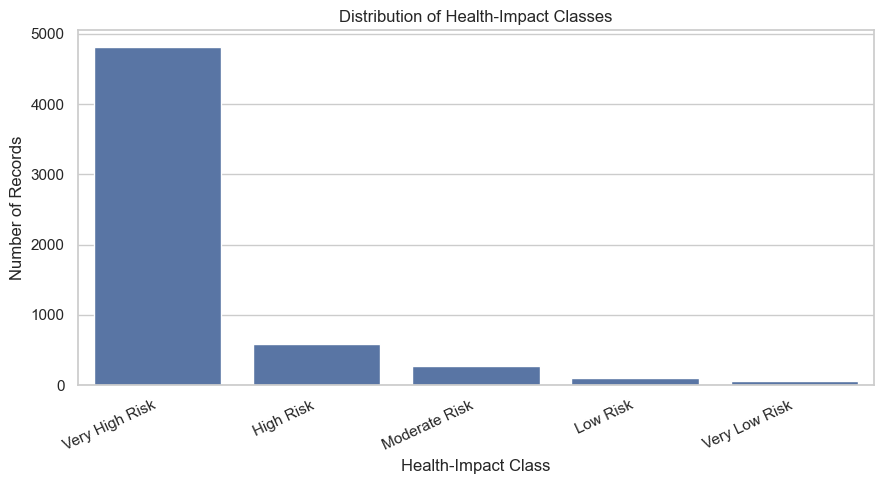

In [3]:
def normalize_column_name(name):
    return "".join(
        character.lower()
        for character in str(name)
        if character.isalnum()
    )

target_aliases = {
    "healthimpactclass",
    "healthriskclass",
    "healthrisk"
}

target_candidates = [
    column for column in df.columns
    if normalize_column_name(column) in target_aliases
]

if not target_candidates:
    raise ValueError(
        "Target column not found. Check the dataset column names."
    )

target_column = next(
    (
        column for column in target_candidates
        if normalize_column_name(column) == "healthimpactclass"
    ),
    target_candidates[0]
)

df = df.dropna(subset=[target_column]).copy()
y = df[target_column]

class_order = sorted(
    y.unique().tolist(),
    key=lambda value: (
        0, value
    ) if isinstance(value, (int, float, np.integer, np.floating))
    else (1, str(value))
)

if (
    normalize_column_name(target_column) == "healthimpactclass"
    and set(class_order) == {0, 1, 2, 3, 4}
):
    class_labels = {
        0: "Very High Risk",
        1: "High Risk",
        2: "Moderate Risk",
        3: "Low Risk",
        4: "Very Low Risk"
    }
elif (
    normalize_column_name(target_column) in {
        "healthrisk", "healthriskclass"
    }
    and set(class_order) == {0, 1, 2}
):
    class_labels = {
        0: "Low Risk",
        1: "Moderate Risk",
        2: "High Risk"
    }
else:
    class_labels = {
        value: f"Class {value}"
        for value in class_order
    }

class_names = [class_labels[value] for value in class_order]

print("Target column:", target_column)
print("Observed target values:", class_order)

display(
    y.value_counts()
    .reindex(class_order)
    .rename(index=class_labels)
    .to_frame("Number of Records")
)

plt.figure(figsize=(9, 5))
sns.countplot(x=y, order=class_order)
plt.xticks(
    range(len(class_order)),
    class_names,
    rotation=25,
    ha="right"
)
plt.title("Distribution of Health-Impact Classes")
plt.xlabel("Health-Impact Class")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()


## Step 5: Feature Selection and Train-Test Split

In this step, we separate the predictor variables (X) from the target variable (y).

### Feature Selection

We exclude the target itself, identifier columns, and variables that could reveal the target or represent downstream health outcomes.

For example, `HealthImpactScore` is excluded when predicting a class derived from that score, because including it could create target leakage.

Target leakage occurs when information that would not legitimately be available at prediction time allows a model to learn the answer indirectly.

### Train-Test Split

We divide the dataset into:

- **80% training data:** Used to train the model.
- **20% testing data:** Reserved for evaluating its performance on unseen records.

We use stratified splitting to preserve the approximate proportion of each target class in both subsets.

This helps provide a more representative evaluation, particularly when the classes are imbalanced.


In [4]:
excluded_names = {
    "id",
    "recordid",
    "healthimpactscore",
    "respiratorycases",
    "cardiovascularcases",
    "hospitaladmissions"
}

excluded_columns = [
    column for column in df.columns
    if column != target_column
    and normalize_column_name(column) in excluded_names
]

X = df.drop(
    columns=[target_column] + excluded_columns
).copy()

y = df[target_column].copy()

all_missing = X.columns[X.isna().all()].tolist()
X = X.drop(columns=all_missing)

print("Excluded columns:", excluded_columns + all_missing)
print("Features used:", X.columns.tolist())
print("Number of features:", X.shape[1])

if X.shape[1] == 0:
    raise ValueError("No usable predictor features remain.")

if y.value_counts().min() < 2:
    raise ValueError(
        "At least one target class has fewer than two records."
    )

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Excluded columns: ['RecordID', 'RespiratoryCases', 'CardiovascularCases', 'HospitalAdmissions', 'HealthImpactScore']
Features used: ['AQI', 'PM10', 'PM2_5', 'NO2', 'SO2', 'O3', 'Temperature', 'Humidity', 'WindSpeed']
Number of features: 9
Training records: 4648
Testing records: 1163



## Step 6: Train the Random Forest Classifier

We use the Random Forest Classifier to predict the health-impact class from the selected environmental features.

### How Does Random Forest Work?

Random Forest is an ensemble learning algorithm that combines predictions from multiple decision trees.

Each tree learns patterns from the training data. The classifier combines their outputs to produce a final predicted class.

### Data Preprocessing

The preprocessing pipeline handles missing values and categorical features:

- Numerical missing values are replaced with the median.
- Categorical missing values are replaced with the most frequent category.
- Categorical features are converted into numerical representations using one-hot encoding.

We also use class weighting to give additional consideration to less frequent classes during training.

Finally, the model is fitted using the training data and generates predictions for the held-out test data.


In [5]:
numeric_features = X_train.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

categorical_features = [
    column for column in X_train.columns
    if column not in numeric_features
]

transformers = []

if numeric_features:
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median"))
    ])

    transformers.append(
        ("numeric", numeric_pipeline, numeric_features)
    )

if categorical_features:
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    transformers.append(
        ("categorical", categorical_pipeline, categorical_features)
    )

preprocessor = ColumnTransformer(
    transformers=transformers
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Random Forest training completed.")

Random Forest training completed.



## Step 7: Evaluate Model Performance

After training the model, we evaluate its predictions using the test dataset.

We use several complementary metrics because accuracy alone may not adequately describe performance when the target classes are imbalanced.

### Evaluation Metrics

- **Accuracy:** The proportion of all test records classified correctly.
- **Balanced Accuracy:** The average recall across the classes.
- **Precision:** The proportion of predicted positive examples for a class that are correct.
- **Recall:** The proportion of actual examples of a class that the model identifies correctly.
- **Macro F1-Score:** The average F1-score across classes, giving each class equal weight.
- **Weighted F1-Score:** The F1-score averaged across classes according to their support.

We also compare the Random Forest model with a majority-class baseline that always predicts the most frequent training class.

This comparison helps determine whether the model provides an improvement over a simple prediction strategy.

The classification report provides additional information about the performance of each individual class.


In [6]:
metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Balanced Accuracy": balanced_accuracy_score(y_test, y_pred),
    "Macro Precision": precision_score(
        y_test, y_pred,
        labels=class_order,
        average="macro",
        zero_division=0
    ),
    "Macro Recall": recall_score(
        y_test, y_pred,
        labels=class_order,
        average="macro",
        zero_division=0
    ),
    "Macro F1-Score": f1_score(
        y_test, y_pred,
        labels=class_order,
        average="macro",
        zero_division=0
    ),
    "Weighted F1-Score": f1_score(
        y_test, y_pred,
        labels=class_order,
        average="weighted",
        zero_division=0
    )
}

display(
    pd.DataFrame(
        metrics.items(),
        columns=["Evaluation Metric", "Score"]
    ).round(4)
)

print("Classification Report:")

print(classification_report(
    y_test,
    y_pred,
    labels=class_order,
    target_names=class_names,
    zero_division=0
))

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

print(
    "Majority Baseline Accuracy:",
    round(accuracy_score(y_test, baseline_pred), 4)
)

,Evaluation Metric,Score
0,Accuracy,0.8985
1,Balanced Accuracy,0.4084
2,Macro Precision,0.6458
3,Macro Recall,0.4084
4,Macro F1-Score,0.4477
5,Weighted F1-Score,0.8809


Classification Report:
                precision    recall  f1-score   support

Very High Risk       0.93      0.99      0.96       962
     High Risk       0.68      0.56      0.62       116
 Moderate Risk       0.62      0.38      0.47        55
      Low Risk       1.00      0.11      0.19        19
 Very Low Risk       0.00      0.00      0.00        11

      accuracy                           0.90      1163
     macro avg       0.65      0.41      0.45      1163
  weighted avg       0.88      0.90      0.88      1163

Majority Baseline Accuracy: 0.8272



## Step 8: Confusion Matrix Visualization

A confusion matrix compares the actual target classes with the classes predicted by the model.

### How to Interpret the Matrix

- **Rows:** Actual classes.
- **Columns:** Predicted classes.
- **Diagonal cells:** Correct predictions.
- **Off-diagonal cells:** Incorrect predictions.

The matrix helps identify which classes the model predicts correctly and which classes it tends to confuse.

We use the actual class values and their verified labels to ensure that the visualization accurately represents the model's results.

This analysis is particularly important when a model achieves high overall accuracy but performs poorly on less frequent classes.


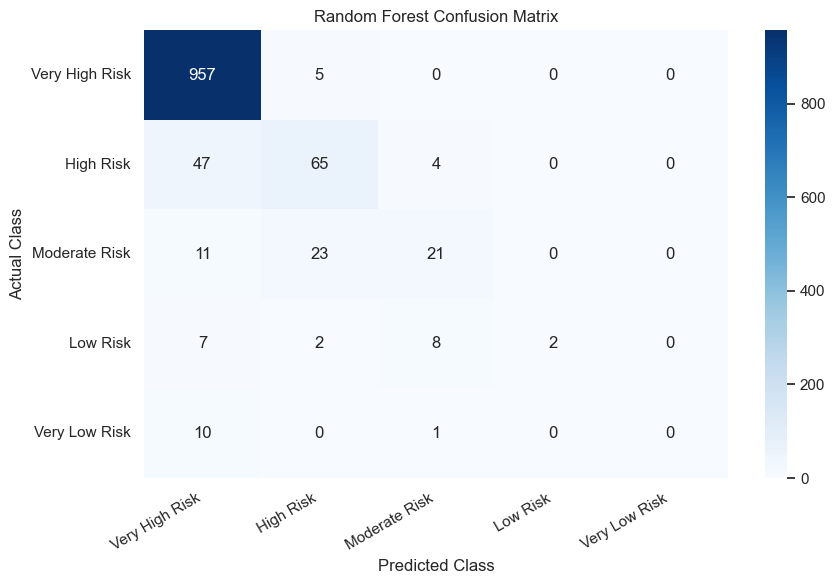

In [7]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=class_order
)

fig, ax = plt.subplots(figsize=(9, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    ax=ax
)

ax.set_title("Random Forest Confusion Matrix")
ax.set_xlabel("Predicted Class")
ax.set_ylabel("Actual Class")

plt.xticks(rotation=30, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


## Step 9: Feature Importance Analysis

Feature importance helps us examine which input features contribute most to the predictions made by the trained Random Forest model.

The notebook extracts the model's feature-importance values and displays the 15 highest-ranked features in a bar chart.

### Why Is Feature Importance Useful?

- It helps identify features that the fitted model relies on most.
- It provides an initial interpretation of the model's predictive behaviour.
- It can guide further investigation of relationships between environmental measurements and the target.

However, feature importance does not establish that a feature causes a particular health outcome. Correlated features can also affect how importance is distributed.

The results should therefore be interpreted as model-based associations rather than evidence of causation.


,Feature,Importance
0,numeric__AQI,0.216432
2,numeric__PM2_5,0.124924
1,numeric__PM10,0.117320
5,numeric__O3,0.110246
3,numeric__NO2,0.095460
8,numeric__WindSpeed,0.091606
7,numeric__Humidity,0.082058
4,numeric__SO2,0.081985
6,numeric__Temperature,0.079968


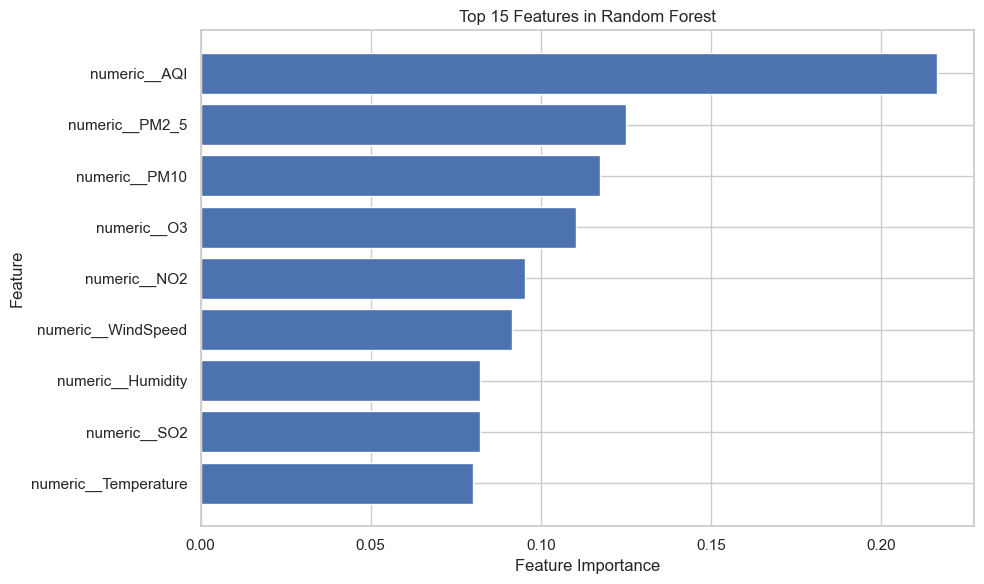

In [8]:
feature_names = (
    model.named_steps["preprocessor"]
    .get_feature_names_out()
)

importance_values = (
    model.named_steps["classifier"]
    .feature_importances_
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
}).sort_values(
    "Importance",
    ascending=False
)

display(importance_df.head(15))

top_features = importance_df.head(15).sort_values(
    "Importance",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 15 Features in Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()


## Step 10: Save Results and Interpret the Findings

In this step, we save the model's test predictions and feature-importance results to CSV files for further analysis and reporting.

### Results to Review

1. The final test-set evaluation metrics.
2. The classification report for each target class.
3. The confusion matrix and the types of classification errors.
4. The most important features identified by the model.
5. The difference between the Random Forest model and the majority-class baseline.

### Limitations

- The model's performance depends on the quality and representativeness of the dataset.
- If the dataset is synthetic, its results cannot establish performance on real populations.
- Feature importance does not prove causation.
- Independent validation is necessary before applying the model to real-world public-health decisions.

### Conclusion

The purpose of this project is to demonstrate a complete machine learning workflow, from data inspection and preprocessing to model training, evaluation, and interpretation.

The final conclusions must be based on the actual results generated by executing the notebook. No performance values should be reported before the model has been evaluated on the test dataset.


In [9]:
results = X_test.copy()

results["Actual_Class"] = y_test
results["Predicted_Class"] = pd.Series(
    y_pred,
    index=y_test.index
)

results["Actual_Label"] = results["Actual_Class"].map(
    class_labels
)

results["Predicted_Label"] = results["Predicted_Class"].map(
    class_labels
)

results.to_csv(
    "eco_health_test_predictions.csv",
    index=False
)

importance_df.to_csv(
    "eco_health_feature_importance.csv",
    index=False
)

print("Results saved successfully.")
print("Files created:")
print("1. eco_health_test_predictions.csv")
print("2. eco_health_feature_importance.csv")

Results saved successfully.
Files created:
1. eco_health_test_predictions.csv
2. eco_health_feature_importance.csv
